# 9주차 과제: 뉴스 기사 단어 빈도 분석 & 시각화

- 분석 대상: news.txt (「기후변화 대응을 위한 도시 녹지 확충」 관련 뉴시스 기사)
- 기사 링크: https://www.newsis.com/view/NISX20250205_0003054569
- 파이프라인: 텍스트 정제 → 형태소 분석(Okt, 명사 추출) → 불용어 제거 → 빈도 계산 → 막대그래프 + 워드클라우드
- 결과 이미지는 `output/` 폴더에 저장됩니다.

## 0. 불용어 리스트
분석 목적(기사의 핵심 주제 파악)과 무관한 단어를 정의합니다.
한 글자 명사(시, 등, 수, 및 …)는 별도로 일괄 제거합니다.

In [1]:
STOPWORDS = {
    # 기사 형식 관련 (언론사, 기자, 인물명)
    "뉴시스", "기자", "이재은", "이수연", "관계자", "국장",
    # 의미가 약한 기능성 명사
    "위해", "위한", "이번", "관련", "통해", "대해", "대한", "이밖에", "아울러",
    "물론", "각종", "번째", "뿐", "점", "이", "를", "향후", "현재", "동시",
    "지난", "까지", "전체", "모습", "다양", "예정", "근거",
}
MIN_LEN = 2   # 이 길이 미만의 명사는 제외
TOP_N = 20    # 시각화할 상위 단어 수

print(f"불용어 {len(STOPWORDS)}개:", sorted(STOPWORDS))

불용어 32개: ['각종', '관계자', '관련', '국장', '근거', '기자', '까지', '뉴시스', '다양', '대한', '대해', '동시', '를', '모습', '물론', '번째', '뿐', '아울러', '예정', '위한', '위해', '이', '이밖에', '이번', '이수연', '이재은', '전체', '점', '지난', '통해', '향후', '현재']


## 1. 환경 설정 및 버전 정보
konlpy는 Java(JDK)가 필요합니다. 과제 폴더의 `.jdk/`에 설치한 JDK가 있으면 JAVA_HOME으로 지정합니다.

In [2]:
import os
import re
import sys
from collections import Counter
from importlib.metadata import version
from pathlib import Path

BASE_DIR = Path.cwd()  # 노트북/스크립트를 과제 폴더에서 실행한다고 가정
OUTPUT_DIR = BASE_DIR / "output"
OUTPUT_DIR.mkdir(exist_ok=True)

local_jdks = sorted((BASE_DIR / ".jdk").glob("jdk*"))
if not os.environ.get("JAVA_HOME") and local_jdks:
    os.environ["JAVA_HOME"] = str(local_jdks[-1])

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from konlpy.tag import Okt
from matplotlib import font_manager
from wordcloud import WordCloud

print("Python     :", sys.version.split()[0])
for pkg in ["konlpy", "JPype1", "pandas", "matplotlib", "seaborn", "wordcloud"]:
    print(f"{pkg:<11}:", version(pkg))
print("JAVA_HOME  :", os.environ.get("JAVA_HOME"))

Python     : 3.12.7
konlpy     : 0.6.0
JPype1     : 1.7.1
pandas     : 3.1.0
matplotlib : 3.11.2
seaborn    : 0.13.2
wordcloud  : 1.9.6
JAVA_HOME  : C:\Users\seong3864\OneDrive\Desktop\year3_sem2\datascience\9week_homework\.jdk\jdk-17.0.20.1+1


## 2. 데이터 불러오기 및 정제
한글 이외의 문자(숫자, 영문, 특수문자 ▲·%↑ 등)를 공백으로 바꾸고, 연속 공백을 하나로 정리합니다.

In [3]:
raw_text = (BASE_DIR / "news.txt").read_text(encoding="utf-8")


def normalize(text: str) -> str:
    """한글만 남기고 불필요한 공백을 정리한다."""
    text = re.sub(r"[^가-힣\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


clean_text = normalize(raw_text)
print("원문 길이:", len(raw_text), "/ 정제 후 길이:", len(clean_text))

원문 길이: 1374 / 정제 후 길이: 1225


## 3. 형태소 분석(명사 추출) 및 불용어 제거

In [4]:
okt = Okt()
nouns = okt.nouns(clean_text)
filtered = [w for w in nouns if len(w) >= MIN_LEN and w not in STOPWORDS]

print("추출 명사 수:", len(nouns))
print("불용어/한 글자 제거 후:", len(filtered))

추출 명사 수: 315
불용어/한 글자 제거 후: 237


## 4. 단어 빈도 계산

In [5]:
freqs = Counter(filtered)
freq_df = pd.DataFrame(freqs.most_common(TOP_N), columns=["단어", "빈도"])
freq_df.index = freq_df.index + 1
freq_df.to_csv(OUTPUT_DIR / "top_words.csv", encoding="utf-8-sig")
freq_df

,단어,빈도
1,공원,19
2,녹지,19
3,계획,16
4,도시,9
5,서울시,6
6,기후,5
7,대응,5
8,기능,4
9,목표,4
10,확충,4


## 5. 한글 폰트 설정

In [6]:
FONT_CANDIDATES = [
    Path("C:/Windows/Fonts/malgun.ttf"),                      # Windows
    Path("/System/Library/Fonts/AppleGothic.ttf"),            # macOS
    Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf"),  # Linux
]
font_path = next((p for p in FONT_CANDIDATES if p.exists()), None)
if font_path is None:
    raise FileNotFoundError("한글 폰트를 찾을 수 없습니다. FONT_CANDIDATES에 경로를 추가하세요.")

font_manager.fontManager.addfont(str(font_path))
font_name = font_manager.FontProperties(fname=str(font_path)).get_name()
sns.set_theme(style="whitegrid", font=font_name)
plt.rcParams["axes.unicode_minus"] = False

## 6. 상위 빈도 단어 막대그래프

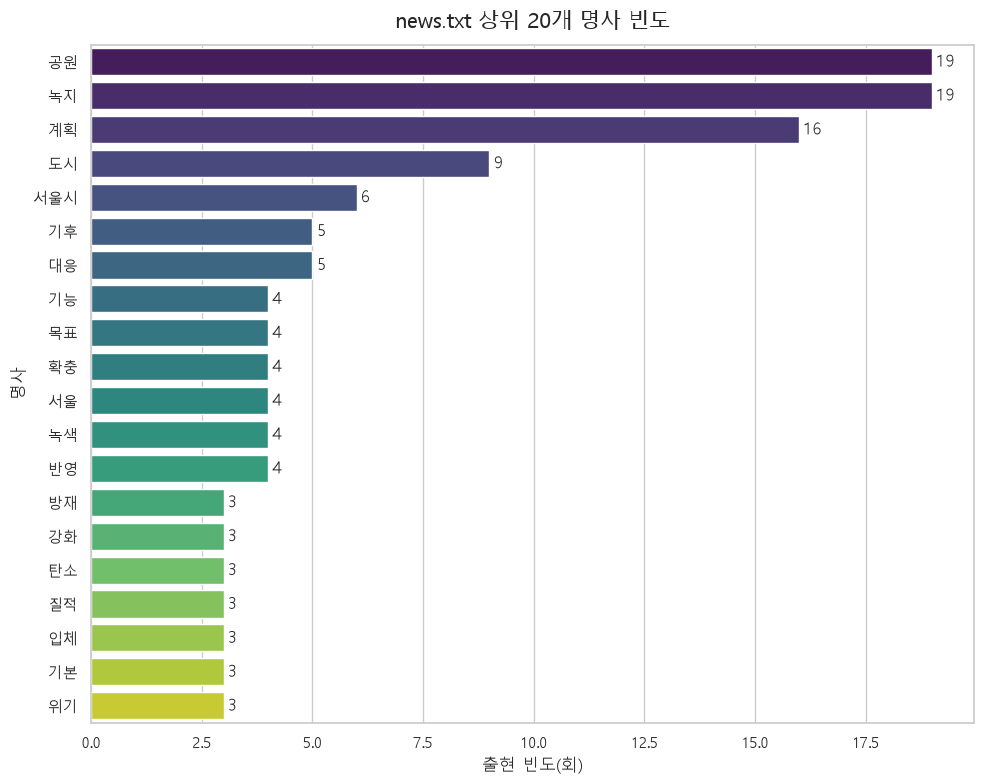

In [7]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=freq_df, x="빈도", y="단어", hue="단어", palette="viridis", legend=False, ax=ax)
for i, count in enumerate(freq_df["빈도"]):
    ax.text(count + 0.1, i, str(count), va="center")
ax.set_title(f"news.txt 상위 {TOP_N}개 명사 빈도", fontsize=15, pad=12)
ax.set_xlabel("출현 빈도(회)")
ax.set_ylabel("명사")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "top20_bar.png", dpi=200)
plt.show()

## 7. 워드 클라우드
막대그래프와 동일한 전처리 결과(`freqs`)를 사용합니다.

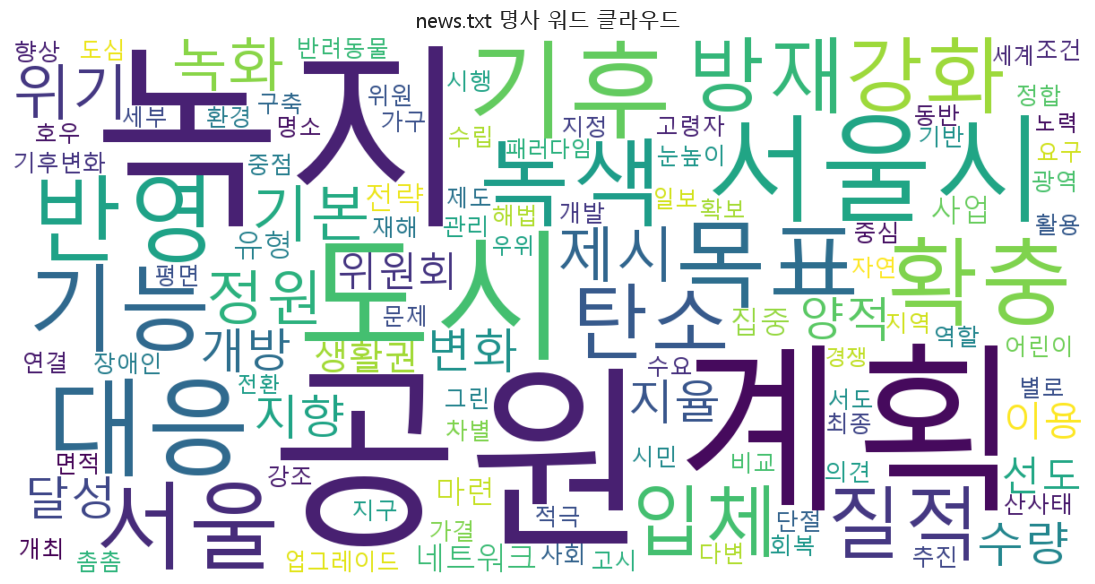

In [8]:
wc = WordCloud(
    font_path=str(font_path),
    background_color="white",
    width=1200,
    height=600,
    colormap="viridis",
    prefer_horizontal=1.0,  # 한글 가독성을 위해 가로 배치만 사용
    random_state=42,
).generate_from_frequencies(freqs)
wc.to_file(str(OUTPUT_DIR / "wordcloud.png"))

plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("news.txt 명사 워드 클라우드", fontsize=15)
plt.tight_layout()
plt.show()

## 8. 결과 해석
- 최빈 단어는 '공원'(19), '녹지'(19), '계획'(16)으로, 기사의 중심 소재가 서울시의 '공원녹지기본계획'임을 보여줍니다.
- '도시'(9), '서울시'(6), '서울'(4)은 분석 대상 지역을, '기후'(5)·'대응'(5)·'위기'(3)·'방재'(3)·'탄소'(3)는
  계획의 목적이 기후 위기 대응과 재해 방지에 있음을 나타냅니다.
- '확충'(4)과 함께 '질적'(3)·'입체'(3)·'기능'(4)·'강화'(3)가 상위에 오른 것은, 단순한 녹지 면적 확대보다
  입체공원 등 녹지의 질적 개선과 기능 강화를 강조하는 기사의 논조와 일치합니다.
- 한계: Okt 명사 추출 시 '공원녹지기본계획'이 '공원/녹지/기본/계획'으로 분리되어 해당 단어들의 빈도가 함께 높아졌습니다.